# AutoML: comparar muchos modelos en varios problemas

**Curso:** Machine Learning para la Toma de Decisiones · Universidad del Pacífico  
**Sesión:** Semana 10

**Objetivo:** usar herramientas de AutoML para evaluar decenas de modelos en tres problemas distintos, analizar por qué el mejor algoritmo cambia según los datos y comparar estos resultados con redes neuronales.

**Contenido**
1. Configuración
2. Ejemplo 1: fuga de clientes (clasificación, datos de negocio)
3. Ejemplo 2: diagnóstico de cáncer de mama (clasificación, datos clínicos)
4. Ejemplo 3: progresión de la diabetes (regresión)
5. Comparación entre ejemplos
6. Redes neuronales frente a otros algoritmos
7. Conclusiones

Anexo: AutoML con PyCaret.

**Herramientas**

| Herramienta | Nivel de AutoML | Qué hace |
|---|---|---|
| LazyPredict | Comparar | Entrena decenas de modelos con hiperparámetros por defecto y los ordena por desempeño. |
| FLAML | Optimizar | Busca algoritmo e hiperparámetros dentro de un presupuesto de tiempo. |
| PyCaret | Comparar | Compara modelos con validación cruzada (`compare_models`). |

## 1. Configuración

In [1]:
!pip install -q "flaml[automl]" lazypredict

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 71.0/71.0 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 223.6/223.6 MB 4.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 353.0/353.0 kB 11.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 351.5/351.5 MB 3.8 MB/s eta 0:00:00


In [2]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
import xgboost as xgb
import tensorflow as tf
from flaml import AutoML
from flaml.automl.data import get_output_from_log
from lazypredict.Supervised import LazyClassifier, LazyRegressor
from sklearn.datasets import load_breast_cancer, load_diabetes, load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, r2_score, mean_squared_error)

SEED = 42
tf.keras.utils.set_random_seed(SEED)
warnings.filterwarnings("ignore")
pd.set_option("display.float_format", "{:.3f}".format)

In [3]:
def evaluar(prob, y_, umbral=0.5):
    pred = (prob >= umbral).astype(int)
    return {"Accuracy": accuracy_score(y_, pred), "Precision": precision_score(y_, pred),
            "Recall": recall_score(y_, pred), "F1": f1_score(y_, pred), "AUC": roc_auc_score(y_, prob)}

def buscar_flaml(X, y, task, metric, tiempo, archivo, estimadores="auto"):
    automl = AutoML()
    automl.fit(X_train=X, y_train=y, task=task, metric=metric, time_budget=tiempo,
               estimator_list=estimadores, eval_method="cv", n_splits=5,
               log_file_name=archivo, log_type="all", seed=SEED, verbose=0)
    hist = pd.read_json(archivo, lines=True).dropna(subset=["learner"])
    hist["Métrica (CV)"] = 1 - hist["validation_loss"]
    resumen = hist.groupby("learner").agg(
        Modelos_probados=("Métrica (CV)", "size"),
        Mejor=("Métrica (CV)", "max"),
        Mediana=("Métrica (CV)", "median"),
    ).sort_values("Mejor", ascending=False).rename_axis("Algoritmo")
    return automl, hist, resumen

resumen_ejemplos = {}

def train_cv_test(automl, X_tr, y_tr, X_te, y_te, task="classification"):
    if task == "classification":
        metrica, tr, te = "AUC", roc_auc_score(y_tr, automl.predict_proba(X_tr)[:, 1]), roc_auc_score(y_te, automl.predict_proba(X_te)[:, 1])
    else:
        metrica, tr, te = "R²", r2_score(y_tr, automl.predict(X_tr)), r2_score(y_te, automl.predict(X_te))
    return pd.Series({f"{metrica} train": tr, f"{metrica} validación cruzada": 1 - automl.best_loss, f"{metrica} test": te},
                     name=automl.best_estimator)

In [4]:
def grafico_ranking(tabla, metrica, titulo, destacar=("LGBM", "XGB")):
    datos = tabla[metrica].sort_values()
    colores = ["#E8892B" if any(d in m for d in destacar) else "#1570BC" for m in datos.index]
    plt.figure(figsize=(8, 0.28 * len(datos) + 1))
    plt.barh(datos.index, datos.values, color=colores)
    plt.xlabel(metrica)
    plt.title(titulo)
    plt.xlim(max(0, datos.min() - 0.05), datos.max() + 0.02)
    plt.tight_layout()
    plt.show()

colores = {"lgbm": "#E8892B", "xgboost": "#000F5A", "rf": "#1570BC", "extra_tree": "#7194CD",
           "xgb_limitdepth": "#9AA8BF", "lrl1": "#4A5578", "catboost": "#C26A12"}

def grafico_busqueda(hist, archivo, tiempo, titulo, etiqueta):
    t, perdida, _, _, _ = get_output_from_log(filename=archivo, time_budget=tiempo)
    plt.figure(figsize=(9, 4.5))
    for algoritmo, datos in hist.groupby("learner"):
        plt.scatter(datos["wall_clock_time"], datos["Métrica (CV)"], s=22, alpha=0.8,
                    color=colores.get(algoritmo, "gray"), label=algoritmo)
    plt.step(t, 1 - np.array(perdida), where="post", color="black", lw=1, label="Mejor hasta el momento")
    q = hist["Métrica (CV)"].quantile(0.05)
    plt.ylim(q - 0.02, hist["Métrica (CV)"].max() + 0.01)
    plt.xlabel("Segundo de búsqueda")
    plt.ylabel(etiqueta)
    plt.title(titulo)
    plt.legend(fontsize=8)
    plt.show()

## 2. Ejemplo 1: fuga de clientes

Mismo caso de las sesiones anteriores: 10,000 clientes, 10 variables y 20% de fuga. Se reutiliza la partición estratificada (60% entrenamiento, 20% validación, 20% prueba).

In [5]:
df = pd.read_csv("/content/Churn_Modelling.csv").drop(columns=["RowNumber", "CustomerId", "Surname"])

CATEGORICAS = ["Geography", "Gender"]
MAPEOS = {col: {v: i for i, v in enumerate(sorted(df[col].unique()))} for col in CATEGORICAS}

def codificar(data):
    data = data.copy()
    for col in CATEGORICAS:
        data[col] = data[col].map(MAPEOS[col])
    return data

X = codificar(df.drop(columns="Exited"))
y = df["Exited"]

X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.25, stratify=y_temp, random_state=SEED)
X_trval, y_trval = pd.concat([X_train, X_val]), pd.concat([y_train, y_val])
print(f"Entrenamiento: {len(X_train)} | Validación: {len(X_val)} | Prueba: {len(X_test)}")

Entrenamiento: 6000 | Validación: 2000 | Prueba: 2000


### 2.1 Nivel 1: comparar muchos modelos con LazyPredict

LazyPredict entrena cerca de 25 clasificadores con sus hiperparámetros por defecto y los ordena. Es una primera exploración: indica qué familias de modelos funcionan mejor antes de invertir tiempo en ajustarlas.

Nota: las columnas F1, Precision y Recall de LazyPredict son promedios ponderados de ambas clases, no solo de la clase "Abandona".

In [7]:
inicio = time.time()
lazy = LazyClassifier(verbose=0, ignore_warnings=True)
tabla_lazy_churn, _ = lazy.fit(X_trval, X_test, y_trval, y_test)
tabla_lazy_churn = tabla_lazy_churn.sort_values("ROC AUC", ascending=False)
print(f"Modelos evaluados: {len(tabla_lazy_churn)} en {time.time() - inicio:.1f} s")
tabla_lazy_churn

Modelos evaluados: 26 en 16.5 s


,Accuracy,Balanced Accuracy,ROC AUC,F1 Score,Precision,Recall,Time Taken
Model,,,,,,,
LGBMClassifier,0.861,0.721,0.854,0.849,0.851,0.861,0.243
AdaBoostClassifier,0.854,0.713,0.848,0.842,0.842,0.854,0.507
RandomForestClassifier,0.861,0.710,0.846,0.846,0.851,0.861,2.338
ExtraTreesClassifier,0.854,0.695,0.842,0.838,0.843,0.854,1.091
XGBClassifier,0.847,0.704,0.831,0.835,0.834,0.847,0.223
SVC,0.856,0.673,0.822,0.832,0.853,0.856,2.190
QuadraticDiscriminantAnalysis,0.829,0.625,0.821,0.798,0.812,0.829,0.157
GaussianNB,0.829,0.608,0.815,0.791,0.818,0.829,0.034
BaggingClassifier,0.839,0.684,0.806,0.825,0.824,0.839,0.496


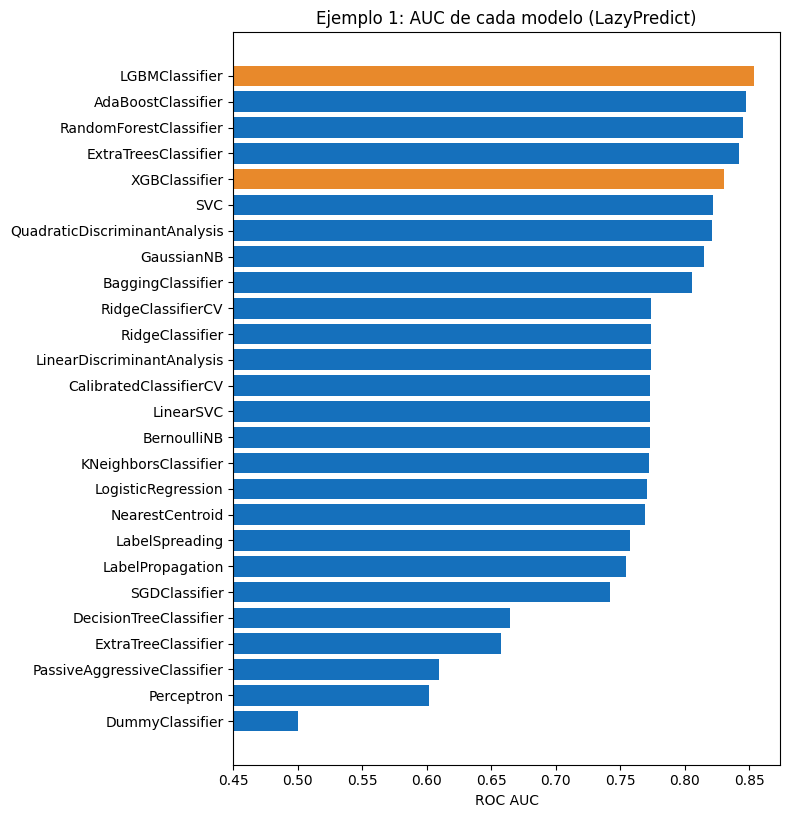

In [8]:
grafico_ranking(tabla_lazy_churn, "ROC AUC", "Ejemplo 1: AUC de cada modelo (LazyPredict)")

### 2.2 ¿Hay sobreajuste en los modelos de LazyPredict?

LazyPredict solo reporta el desempeño en prueba. Con `provide_models()` se recuperan los modelos ya entrenados y se puede calcular también el desempeño en entrenamiento. Una brecha grande entre ambos indica sobreajuste.

In [9]:
modelos_lazy = lazy.provide_models(X_trval, X_test, y_trval, y_test)

filas = {}
for nombre, modelo in modelos_lazy.items():
    if hasattr(modelo, "predict_proba"):
        auc_tr = roc_auc_score(y_trval, modelo.predict_proba(X_trval)[:, 1])
        auc_te = roc_auc_score(y_test, modelo.predict_proba(X_test)[:, 1])
        filas[nombre] = {"AUC train": auc_tr, "AUC test": auc_te, "Brecha": auc_tr - auc_te}

sobreajuste_lazy = pd.DataFrame(filas).T.sort_values("AUC test", ascending=False)
sobreajuste_lazy

,AUC train,AUC test,Brecha
LGBMClassifier,0.967,0.854,0.113
AdaBoostClassifier,0.845,0.848,-0.002
RandomForestClassifier,1.000,0.846,0.154
ExtraTreesClassifier,1.000,0.842,0.158
XGBClassifier,0.994,0.831,0.163
QuadraticDiscriminantAnalysis,0.817,0.821,-0.004
GaussianNB,0.805,0.815,-0.010
BaggingClassifier,0.999,0.806,0.193
LinearDiscriminantAnalysis,0.755,0.774,-0.019
CalibratedClassifierCV,0.755,0.773,-0.019


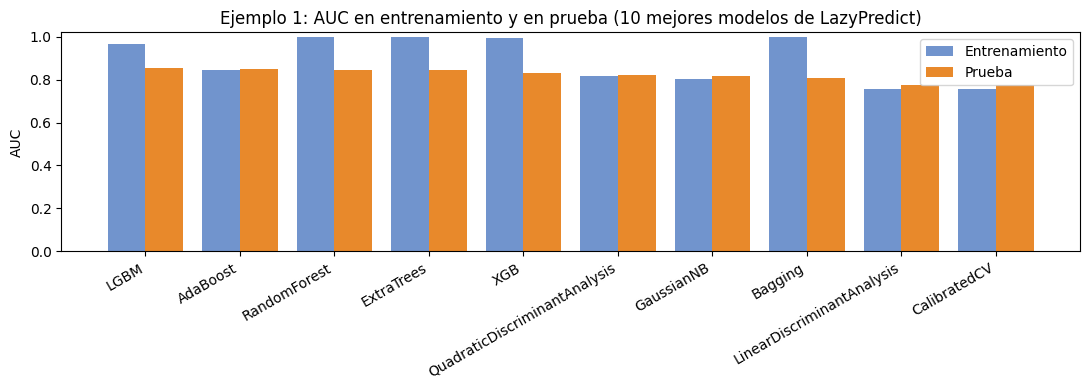

In [12]:
datos = sobreajuste_lazy.head(10)
x = np.arange(len(datos))
plt.figure(figsize=(11, 4))
plt.bar(x - 0.2, datos["AUC train"], width=0.4, color="#7194CD", label="Entrenamiento")
plt.bar(x + 0.2, datos["AUC test"], width=0.4, color="#E8892B", label="Prueba")
plt.xticks(x, [n.replace("Classifier", "") for n in datos.index], rotation=30, ha="right")
plt.ylim(0, 1.02)
plt.ylabel("AUC")
plt.title("Ejemplo 1: AUC en entrenamiento y en prueba (10 mejores modelos de LazyPredict)")
plt.legend()
plt.tight_layout()
plt.show()

Con hiperparámetros por defecto, varios modelos (Random Forest, Extra Trees, XGBoost, Bagging) logran un AUC cercano a 1 en entrenamiento: memorizan los datos. Por eso LazyPredict sirve para explorar, pero no para elegir el modelo final sin ajustarlo.

### 2.3 Nivel 2: optimizar con FLAML

LazyPredict usa hiperparámetros por defecto. FLAML, en cambio, busca la mejor combinación de algoritmo e hiperparámetros dentro de un presupuesto de tiempo, usando validación cruzada. Con `log_type="all"` se registra cada modelo evaluado.

| Parámetro | Función |
|---|---|
| `metric` | Métrica que se optimiza. |
| `time_budget` | Segundos de búsqueda. |
| `estimator_list` | Algoritmos candidatos. |
| `eval_method`, `n_splits` | Validación cruzada de 5 particiones. |

In [13]:
inicio = time.time()
automl_churn, hist_churn, resumen_churn = buscar_flaml(
    X_trval, y_trval, task="classification", metric="roc_auc", tiempo=120,
    archivo="flaml_churn.log", estimadores=["lgbm", "xgboost", "rf", "extra_tree"])
tiempo_flaml = time.time() - inicio

print("Modelos evaluados:", len(hist_churn))
print("Mejor algoritmo:", automl_churn.best_estimator)
print("AUC (CV):", round(1 - automl_churn.best_loss, 4))
resumen_churn

Modelos evaluados: 163
Mejor algoritmo: lgbm
AUC (CV): 0.8665


,Modelos_probados,Mejor,Mediana
Algoritmo,,,
lgbm,78,0.867,0.859
xgboost,35,0.866,0.856
rf,32,0.859,0.831
extra_tree,18,0.841,0.824


### 2.4 ¿Hay sobreajuste en el modelo de FLAML?

En AutoML se comparan tres valores. La comparación más importante es **validación cruzada frente a prueba**: FLAML eligió el modelo según la validación cruzada, de modo que si ambos valores coinciden, la búsqueda no se sobreajustó a la validación. La brecha con entrenamiento se interpreta como siempre.

In [14]:
train_cv_test(automl_churn, X_trval, y_trval, X_test, y_test).to_frame()

,lgbm
AUC train,0.920
AUC validación cruzada,0.867
AUC test,0.863


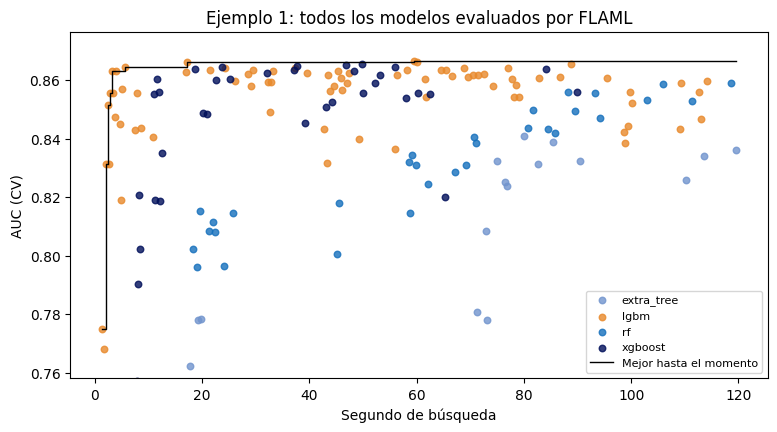

In [15]:
grafico_busqueda(hist_churn, "flaml_churn.log", 120, "Ejemplo 1: todos los modelos evaluados por FLAML", "AUC (CV)")

In [16]:
with pd.option_context("display.max_rows", None, "display.max_colwidth", 120):
    display(hist_churn.sort_values("Métrica (CV)", ascending=False)
            [["learner", "Métrica (CV)", "trial_time", "wall_clock_time", "config"]]
            .rename(columns={"learner": "Algoritmo", "Métrica (CV)": "AUC (CV)", "trial_time": "Tiempo (s)",
                             "wall_clock_time": "Segundo de búsqueda", "config": "Hiperparámetros"})
            .reset_index(drop=True))

,Algoritmo,AUC (CV),Tiempo (s),Segundo de búsqueda,Hiperparámetros
0,lgbm,0.867,0.479,59.532,"{'n_estimators': 54, 'num_leaves': 18, 'min_child_samples': 8, 'learning_rate': 0.129308758571856, 'log_max_bin': 8,..."
1,lgbm,0.866,0.223,60.055,"{'n_estimators': 26, 'num_leaves': 9, 'min_child_samples': 18, 'learning_rate': 0.338217578911845, 'log_max_bin': 8,..."
2,lgbm,0.866,0.256,17.257,"{'n_estimators': 26, 'num_leaves': 9, 'min_child_samples': 17, 'learning_rate': 0.338217578911845, 'log_max_bin': 8,..."
3,xgboost,0.866,0.568,49.829,"{'n_estimators': 78, 'max_leaves': 8, 'min_child_weight': 2.760769982213273, 'learning_rate': 0.095034520682163, 'su..."
4,lgbm,0.866,0.697,88.840,"{'n_estimators': 71, 'num_leaves': 29, 'min_child_samples': 10, 'learning_rate': 0.053748374765227, 'log_max_bin': 8..."
5,xgboost,0.865,0.750,46.823,"{'n_estimators': 108, 'max_leaves': 9, 'min_child_weight': 0.556519343094111, 'learning_rate': 0.11518509828866401, ..."
6,xgboost,0.865,0.433,37.769,"{'n_estimators': 35, 'max_leaves': 16, 'min_child_weight': 0.278476495291791, 'learning_rate': 0.148415459967035, 's..."
7,xgboost,0.865,1.104,23.734,"{'n_estimators': 188, 'max_leaves': 7, 'min_child_weight': 0.270293819938834, 'learning_rate': 0.07333366414546601, ..."
8,xgboost,0.865,2.770,55.919,"{'n_estimators': 92, 'max_leaves': 9, 'min_child_weight': 9.246853642640449, 'learning_rate': 0.126912122615623, 'su..."
9,lgbm,0.864,0.521,5.596,"{'n_estimators': 127, 'num_leaves': 4, 'min_child_samples': 17, 'learning_rate': 0.173801681747905, 'log_max_bin': 8..."


Mejor configuración de cada algoritmo, reentrenada y evaluada en el conjunto de prueba:

In [17]:
from flaml.automl.model import LGBMEstimator, XGBoostSklearnEstimator, RandomForestEstimator, ExtraTreesEstimator

clases = {"lgbm": LGBMEstimator, "xgboost": XGBoostSklearnEstimator,
          "rf": RandomForestEstimator, "extra_tree": ExtraTreesEstimator}
resultados_flaml = {}
for algoritmo, config in automl_churn.best_config_per_estimator.items():
    if config is None:
        continue
    modelo = clases[algoritmo](task="classification", **config)
    modelo.fit(X_trval, y_trval)
    prob = modelo.predict_proba(X_test)[:, 1]
    resultados_flaml[algoritmo] = {**evaluar(prob, y_test),
                                   "AUC train": roc_auc_score(y_trval, modelo.predict_proba(X_trval)[:, 1]),
                                   "AUC (CV)": 1 - automl_churn.best_loss_per_estimator[algoritmo]}

pd.DataFrame(resultados_flaml).T.sort_values("AUC (CV)", ascending=False)

,Accuracy,Precision,Recall,F1,AUC,AUC train,AUC (CV)
lgbm,0.863,0.767,0.469,0.582,0.863,0.920,0.867
xgboost,0.866,0.773,0.484,0.595,0.868,0.887,0.866
rf,0.862,0.775,0.450,0.569,0.854,0.960,0.859
extra_tree,0.823,0.965,0.135,0.237,0.846,0.847,0.841


In [18]:
prob_flaml = automl_churn.predict_proba(X_test)[:, 1]
resumen_ejemplos["1. Fuga de clientes"] = {
    "Tipo": "Clasificación", "Observaciones": len(df), "Variables": X.shape[1], "Métrica": "AUC",
    "Modelos LazyPredict": len(tabla_lazy_churn),
    "Mejor LazyPredict": tabla_lazy_churn.index[0], "Valor LazyPredict": tabla_lazy_churn["ROC AUC"].iloc[0],
    "Modelos FLAML": len(hist_churn), "Mejor FLAML": automl_churn.best_estimator,
    "Valor FLAML (prueba)": roc_auc_score(y_test, prob_flaml)}

### 2.5 Usar el modelo elegido: predicción para nuevos clientes

Una vez elegido el modelo, se usa igual que cualquier modelo de scikit-learn. Se predicen los dos clientes del caso de la sesión anterior, con la misma codificación del entrenamiento y el umbral de 0.35.

In [19]:
nuevos_clientes = pd.DataFrame([
    {"CreditScore": 580, "Geography": "Germany", "Gender": "Male", "Age": 52, "Tenure": 2,
     "Balance": 0.0, "NumOfProducts": 1, "HasCrCard": 0, "IsActiveMember": 0, "EstimatedSalary": 45000.0},
    {"CreditScore": 710, "Geography": "Spain", "Gender": "Female", "Age": 30, "Tenure": 8,
     "Balance": 120000.0, "NumOfProducts": 2, "HasCrCard": 1, "IsActiveMember": 1, "EstimatedSalary": 95000.0},
], index=["Cliente 1", "Cliente 2"])

X_nuevos = codificar(nuevos_clientes)[X.columns]
UMBRAL = 0.35

**Opción A: el mejor modelo de FLAML.** El objeto `automl` ya contiene el modelo reentrenado con la mejor configuración.

In [20]:
prob_a = automl_churn.predict_proba(X_nuevos)[:, 1]
pd.DataFrame({"Probabilidad de fuga": prob_a, "Predicción": np.where(prob_a >= UMBRAL, "Abandona", "Permanece")},
             index=X_nuevos.index)

,Probabilidad de fuga,Predicción
Cliente 1,0.842,Abandona
Cliente 2,0.056,Permanece


**Opción B: un modelo de LazyPredict.** Se toma el modelo elegido del diccionario `modelos_lazy` (incluye su preprocesamiento).

In [ ]:
elegido = "AdaBoostClassifier"
prob_b = modelos_lazy[elegido].predict_proba(X_nuevos)[:, 1]
pd.DataFrame({"Probabilidad de fuga": prob_b, "Predicción": np.where(prob_b >= UMBRAL, "Abandona", "Permanece")},
             index=X_nuevos.index)

,Probabilidad de fuga,Predicción
Cliente 1,0.542,Abandona
Cliente 2,0.306,Permanece


Las probabilidades de AdaBoost se concentran cerca de 0.5, por lo que no son comparables con las de FLAML. El umbral de 0.35 se definió para los modelos de boosting de la sesión anterior: si eliges otro modelo, revisa su umbral con el conjunto de validación antes de usarlo.

Para usar el modelo después, sin volver a entrenarlo, se guarda en un archivo y se carga cuando se necesite:

In [21]:
import joblib
joblib.dump(automl_churn, "modelo_fuga_flaml.pkl")
modelo_cargado = joblib.load("modelo_fuga_flaml.pkl")
modelo_cargado.predict_proba(X_nuevos)[:, 1]

array([0.84210828, 0.05599122])

## 3. Ejemplo 2: diagnóstico de cáncer de mama

Conjunto de datos clínicos incluido en scikit-learn: 569 tumores descritos por 30 medidas obtenidas de imágenes de biopsia. En este conjunto, el target vale 0 para tumores malignos y 1 para benignos.

In [23]:
from sklearn.datasets import load_breast_cancer

# Cargar el conjunto de datos como un objeto Bunch
cancer = load_breast_cancer()

# Acceder a las características y etiquetas
X = cancer.data  # Matriz de forma (569, 30)
y = cancer.target  # Array de etiquetas (569,)

# Cargar directamente como tupla (X, y) o DataFrames de pandas
import pandas as pd

df_X, df_y = load_breast_cancer(return_X_y=True, as_frame=True)

In [24]:
df_X

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.990,10.380,122.800,1001.000,0.118,0.278,0.300,0.147,0.242,0.079,...,25.380,17.330,184.600,2019.000,0.162,0.666,0.712,0.265,0.460,0.119
1,20.570,17.770,132.900,1326.000,0.085,0.079,0.087,0.070,0.181,0.057,...,24.990,23.410,158.800,1956.000,0.124,0.187,0.242,0.186,0.275,0.089
2,19.690,21.250,130.000,1203.000,0.110,0.160,0.197,0.128,0.207,0.060,...,23.570,25.530,152.500,1709.000,0.144,0.424,0.450,0.243,0.361,0.088
3,11.420,20.380,77.580,386.100,0.142,0.284,0.241,0.105,0.260,0.097,...,14.910,26.500,98.870,567.700,0.210,0.866,0.687,0.258,0.664,0.173
4,20.290,14.340,135.100,1297.000,0.100,0.133,0.198,0.104,0.181,0.059,...,22.540,16.670,152.200,1575.000,0.137,0.205,0.400,0.163,0.236,0.077
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,21.560,22.390,142.000,1479.000,0.111,0.116,0.244,0.139,0.173,0.056,...,25.450,26.400,166.100,2027.000,0.141,0.211,0.411,0.222,0.206,0.071
565,20.130,28.250,131.200,1261.000,0.098,0.103,0.144,0.098,0.175,0.055,...,23.690,38.250,155.000,1731.000,0.117,0.192,0.322,0.163,0.257,0.066
566,16.600,28.080,108.300,858.100,0.085,0.102,0.093,0.053,0.159,0.056,...,18.980,34.120,126.700,1124.000,0.114,0.309,0.340,0.142,0.222,0.078
567,20.600,29.330,140.100,1265.000,0.118,0.277,0.351,0.152,0.240,0.070,...,25.740,39.420,184.600,1821.000,0.165,0.868,0.939,0.265,0.409,0.124


In [25]:
Xc, yc = load_breast_cancer(return_X_y=True, as_frame=True)
print(Xc.shape)
print(yc.value_counts().rename(index={0: "Maligno", 1: "Benigno"}))
Xc_tr, Xc_te, yc_tr, yc_te = train_test_split(Xc, yc, test_size=0.20, stratify=yc, random_state=SEED)

(569, 30)
target
Benigno    357
Maligno    212
Name: count, dtype: int64


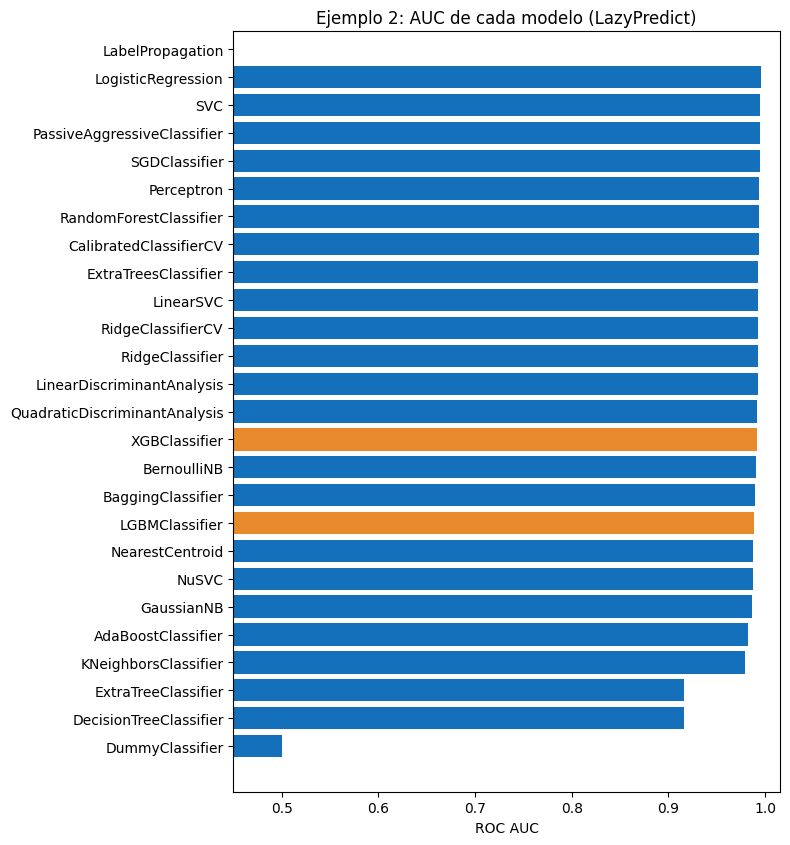

,Accuracy,Balanced Accuracy,ROC AUC,F1 Score,Precision,Recall,Time Taken
Model,,,,,,,
LogisticRegression,0.982,0.981,0.995,0.982,0.982,0.982,0.043
SVC,0.982,0.981,0.995,0.982,0.982,0.982,0.044
PassiveAggressiveClassifier,0.991,0.988,0.995,0.991,0.991,0.991,0.029
SGDClassifier,0.965,0.967,0.994,0.965,0.966,0.965,0.035
Perceptron,0.956,0.960,0.994,0.956,0.958,0.956,0.028
RandomForestClassifier,0.956,0.950,0.994,0.956,0.956,0.956,0.352
CalibratedClassifierCV,0.974,0.964,0.994,0.973,0.975,0.974,0.078
ExtraTreesClassifier,0.956,0.950,0.993,0.956,0.956,0.956,0.180
LinearSVC,0.965,0.962,0.993,0.965,0.965,0.965,0.036


In [26]:
tabla_lazy_cancer, _ = LazyClassifier(verbose=0, ignore_warnings=True).fit(Xc_tr, Xc_te, yc_tr, yc_te)
tabla_lazy_cancer = tabla_lazy_cancer.sort_values(["ROC AUC", "Accuracy"], ascending=False)
grafico_ranking(tabla_lazy_cancer, "ROC AUC", "Ejemplo 2: AUC de cada modelo (LazyPredict)")
tabla_lazy_cancer.head(10)

In [27]:
automl_cancer, hist_cancer, resumen_cancer = buscar_flaml(
    Xc_tr, yc_tr, task="classification", metric="roc_auc", tiempo=60, archivo="flaml_cancer.log")
auc_cancer = roc_auc_score(yc_te, automl_cancer.predict_proba(Xc_te)[:, 1])
print(f"Mejor algoritmo: {automl_cancer.best_estimator} | AUC en prueba: {auc_cancer:.3f}")
display(train_cv_test(automl_cancer, Xc_tr, yc_tr, Xc_te, yc_te).to_frame())
resumen_cancer

INFO:flaml.tune.searcher.blendsearch:No low-cost partial config given to the search algorithm. For cost-frugal search, consider providing low-cost values for cost-related hps via 'low_cost_partial_config'. More info can be found at https://microsoft.github.io/FLAML/docs/FAQ#about-low_cost_partial_config-in-tune
INFO:flaml.tune.searcher.blendsearch:No low-cost partial config given to the search algorithm. For cost-frugal search, consider providing low-cost values for cost-related hps via 'low_cost_partial_config'. More info can be found at https://microsoft.github.io/FLAML/docs/FAQ#about-low_cost_partial_config-in-tune


Mejor algoritmo: xgboost | AUC en prueba: 0.992


,xgboost
AUC train,1.000
AUC validación cruzada,0.998
AUC test,0.992


,Modelos_probados,Mejor,Mediana
Algoritmo,,,
xgboost,27,0.998,0.992
lgbm,51,0.996,0.993
extra_tree,15,0.991,0.985
rf,10,0.987,0.983
xgb_limitdepth,1,0.984,0.984
sgd,24,0.971,0.959
lrl1,1,0.941,0.941


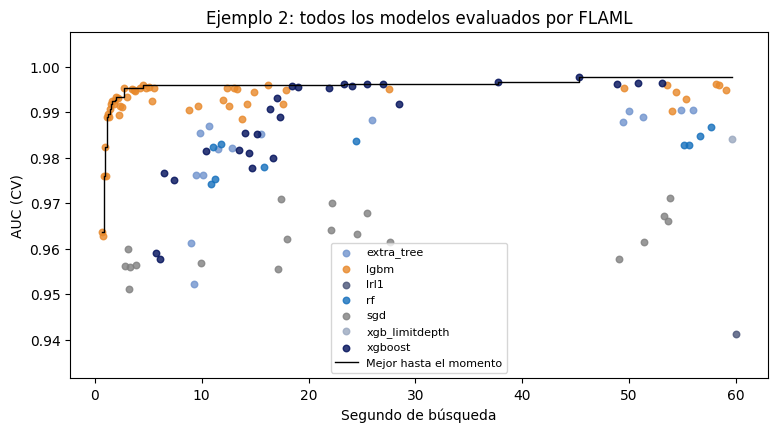

In [28]:
grafico_busqueda(hist_cancer, "flaml_cancer.log", 60, "Ejemplo 2: todos los modelos evaluados por FLAML", "AUC (CV)")
resumen_ejemplos["2. Cáncer de mama"] = {
    "Tipo": "Clasificación", "Observaciones": len(Xc), "Variables": Xc.shape[1], "Métrica": "AUC",
    "Modelos LazyPredict": len(tabla_lazy_cancer),
    "Mejor LazyPredict": tabla_lazy_cancer.index[0], "Valor LazyPredict": tabla_lazy_cancer["ROC AUC"].iloc[0],
    "Modelos FLAML": len(hist_cancer), "Mejor FLAML": automl_cancer.best_estimator, "Valor FLAML (prueba)": auc_cancer}

## 4. Ejemplo 3: progresión de la diabetes (regresión)

442 pacientes descritos por 10 variables (edad, sexo, índice de masa corporal, presión arterial y seis medidas de sangre, ya estandarizadas). El target es una medida cuantitativa de la progresión de la enfermedad un año después. Este ejemplo anticipa la unidad de regresión (semana 11): las métricas son $R^2$ y RMSE.

Modelos evaluados: 42


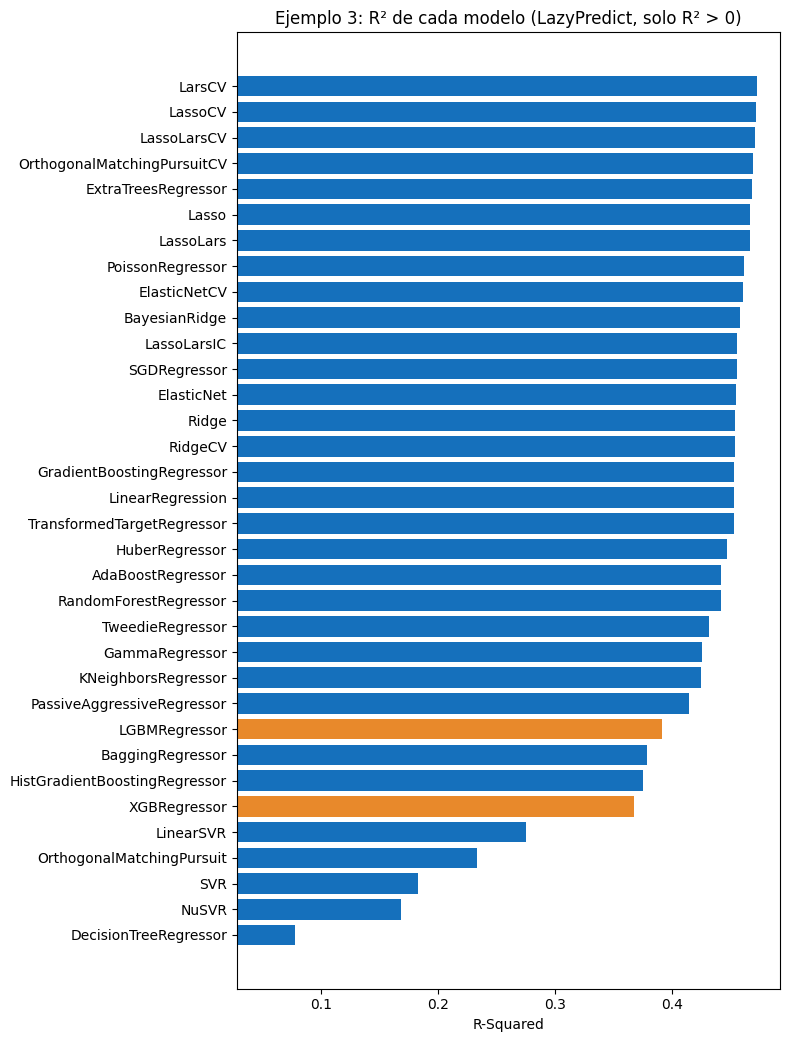

,Adjusted R-Squared,R-Squared,RMSE,Time Taken
Model,,,,
LarsCV,0.405,0.472,52.872,0.061
LassoCV,0.404,0.471,52.920,0.084
LassoLarsCV,0.404,0.471,52.921,0.026
OrthogonalMatchingPursuitCV,0.401,0.469,53.022,0.016
ExtraTreesRegressor,0.400,0.468,53.068,0.402
Lasso,0.399,0.467,53.147,0.014
LassoLars,0.399,0.467,53.147,0.014
PoissonRegressor,0.392,0.461,53.431,0.017
ElasticNetCV,0.392,0.461,53.441,0.117


In [29]:
Xd, yd = load_diabetes(return_X_y=True, as_frame=True)
Xd_tr, Xd_te, yd_tr, yd_te = train_test_split(Xd, yd, test_size=0.20, random_state=SEED)

tabla_lazy_diab, _ = LazyRegressor(verbose=0, ignore_warnings=True).fit(Xd_tr, Xd_te, yd_tr, yd_te)
tabla_lazy_diab = tabla_lazy_diab.sort_values("R-Squared", ascending=False)
print("Modelos evaluados:", len(tabla_lazy_diab))
grafico_ranking(tabla_lazy_diab[tabla_lazy_diab["R-Squared"] > 0], "R-Squared",
                "Ejemplo 3: R² de cada modelo (LazyPredict, solo R² > 0)", destacar=("LGBM", "XGB"))
tabla_lazy_diab.head(10)

In [30]:
automl_diab, hist_diab, resumen_diab = buscar_flaml(
    Xd_tr, yd_tr, task="regression", metric="r2", tiempo=60, archivo="flaml_diab.log")
pred_diab = automl_diab.predict(Xd_te)
r2_diab = r2_score(yd_te, pred_diab)
print(f"Mejor algoritmo: {automl_diab.best_estimator} | R² en prueba: {r2_diab:.3f} | "
      f"RMSE: {np.sqrt(mean_squared_error(yd_te, pred_diab)):.1f}")
display(train_cv_test(automl_diab, Xd_tr, yd_tr, Xd_te, yd_te, task="regression").to_frame())
resumen_diab

INFO:flaml.tune.searcher.blendsearch:No low-cost partial config given to the search algorithm. For cost-frugal search, consider providing low-cost values for cost-related hps via 'low_cost_partial_config'. More info can be found at https://microsoft.github.io/FLAML/docs/FAQ#about-low_cost_partial_config-in-tune


Mejor algoritmo: sgd | R² en prueba: 0.458 | RMSE: 53.6


,sgd
R² train,0.513
R² validación cruzada,0.480
R² test,0.458


,Modelos_probados,Mejor,Mediana
Algoritmo,,,
sgd,166,0.480,0.465
xgb_limitdepth,38,0.449,0.395
xgboost,44,0.442,0.367
lgbm,30,0.439,0.415
rf,24,0.432,0.416
extra_tree,14,0.431,0.409


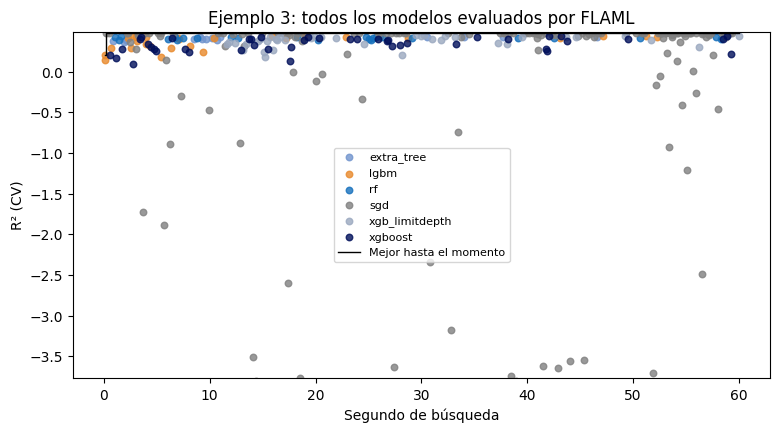

In [32]:
grafico_busqueda(hist_diab, "flaml_diab.log", 60, "Ejemplo 3: todos los modelos evaluados por FLAML", "R² (CV)")
resumen_ejemplos["3. Diabetes (regresión)"] = {
    "Tipo": "Regresión", "Observaciones": len(Xd), "Variables": Xd.shape[1], "Métrica": "R²",
    "Modelos LazyPredict": len(tabla_lazy_diab),
    "Mejor LazyPredict": tabla_lazy_diab.index[0], "Valor LazyPredict": tabla_lazy_diab["R-Squared"].iloc[0],
    "Modelos FLAML": len(hist_diab), "Mejor FLAML": automl_diab.best_estimator, "Valor FLAML (prueba)": r2_diab}

## 5. Comparación entre ejemplos

In [33]:
pd.DataFrame(resumen_ejemplos).T

,Tipo,Observaciones,Variables,Métrica,Modelos LazyPredict,Mejor LazyPredict,Valor LazyPredict,Modelos FLAML,Mejor FLAML,Valor FLAML (prueba)
1. Fuga de clientes,Clasificación,10000,10,AUC,26,LGBMClassifier,0.854,163,lgbm,0.863
2. Cáncer de mama,Clasificación,569,30,AUC,27,LogisticRegression,0.995,129,xgboost,0.992
3. Diabetes (regresión),Regresión,442,10,R²,42,LarsCV,0.472,316,sgd,0.458


El mejor modelo **cambia según el problema**. En datos de negocio con relaciones no lineales (fuga de clientes) dominan los métodos de boosting; en conjuntos pequeños con relaciones cercanas a lineales (cáncer de mama, diabetes) los modelos lineales compiten o ganan. Este resultado ilustra el teorema de *no free lunch*: ningún algoritmo es el mejor para todos los problemas, y por eso tiene sentido comparar muchos modelos.

## 6. Redes neuronales frente a otros algoritmos

### 6.1 Datos tabulares: fuga de clientes

La red requiere codificación one-hot de `Geography` y escalamiento de las variables. El `StandardScaler` se ajusta solo con el conjunto de entrenamiento.

In [34]:
def preparar_ann(data):
    return pd.get_dummies(data, columns=["Geography"], dtype=float)

Xtr_ann, Xval_ann, Xte_ann = preparar_ann(X_train), preparar_ann(X_val), preparar_ann(X_test)
scaler = StandardScaler().fit(Xtr_ann)
Xtr_ann, Xval_ann, Xte_ann = (scaler.transform(d) for d in (Xtr_ann, Xval_ann, Xte_ann))

ann = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(Xtr_ann.shape[1],)),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(16, activation="relu"),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(1, activation="sigmoid"),
])
ann.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3), loss="binary_crossentropy",
            metrics=[tf.keras.metrics.AUC(name="auc")])
early = tf.keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=15, restore_best_weights=True)

inicio = time.time()
historial = ann.fit(Xtr_ann, y_train, validation_data=(Xval_ann, y_val),
                    epochs=200, batch_size=64, callbacks=[early], verbose=0)
tiempo_ann = time.time() - inicio
prob_ann = ann.predict(Xte_ann, verbose=0).ravel()
print("Épocas entrenadas:", len(historial.history["loss"]))

Épocas entrenadas: 96


In [35]:
inicio = time.time()
lgb_model = lgb.LGBMClassifier(n_estimators=2000, learning_rate=0.05, num_leaves=15, min_child_samples=30,
                               subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=SEED, verbose=-1)
lgb_model.fit(X_train, y_train, eval_set=[(X_val, y_val)], eval_metric="auc",
              categorical_feature=["Geography"], callbacks=[lgb.early_stopping(50, verbose=False)])
tiempo_lgb = time.time() - inicio

probabilidades = {"LightGBM (manual)": lgb_model.predict_proba(X_test)[:, 1],
                  "FLAML": prob_flaml, "Red neuronal": prob_ann}
tabla_churn = pd.DataFrame({n: evaluar(p, y_test) for n, p in probabilidades.items()}).T
tabla_churn["Tiempo (s)"] = [tiempo_lgb, tiempo_flaml, tiempo_ann]
tabla_churn

,Accuracy,Precision,Recall,F1,AUC,Tiempo (s)
LightGBM (manual),0.867,0.789,0.469,0.589,0.866,0.247
FLAML,0.863,0.767,0.469,0.582,0.863,120.932
Red neuronal,0.865,0.809,0.437,0.568,0.861,38.812


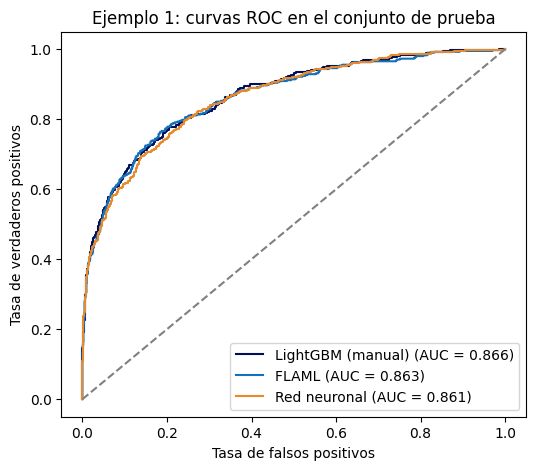

In [36]:
plt.figure(figsize=(6, 5))
for (nombre, prob), color in zip(probabilidades.items(), ["#000F5A", "#1570BC", "#E8892B"]):
    fpr, tpr, _ = roc_curve(y_test, prob)
    plt.plot(fpr, tpr, color=color, label=f"{nombre} (AUC = {roc_auc_score(y_test, prob):.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray")
plt.xlabel("Tasa de falsos positivos")
plt.ylabel("Tasa de verdaderos positivos")
plt.title("Ejemplo 1: curvas ROC en el conjunto de prueba")
plt.legend()
plt.show()

### 6.2 Imágenes: reconocimiento de dígitos escritos a mano

1,797 imágenes de 8×8 píxeles con dígitos del 0 al 9. Aquí cada variable es un píxel y la posición de los píxeles importa: es el tipo de dato para el que se diseñaron las redes convolucionales (CNN), que analizan grupos de píxeles vecinos.

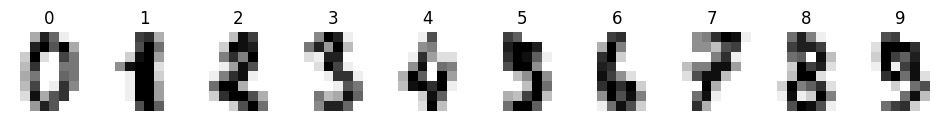

In [37]:
Xg, yg = load_digits(return_X_y=True)
fig, axes = plt.subplots(1, 10, figsize=(12, 1.6))
for ax, imagen, etiqueta in zip(axes, Xg[:10], yg[:10]):
    ax.imshow(imagen.reshape(8, 8), cmap="gray_r")
    ax.set_title(etiqueta)
    ax.axis("off")
plt.show()

Xg_tr, Xg_te, yg_tr, yg_te = train_test_split(Xg, yg, test_size=0.20, stratify=yg, random_state=SEED)
Xg_fit, Xg_val, yg_fit, yg_val = train_test_split(Xg_tr, yg_tr, test_size=0.20, stratify=yg_tr, random_state=SEED)

In [38]:
clasicos = {
    "Regresión logística": LogisticRegression(max_iter=3000),
    "SVM (kernel RBF)": SVC(),
    "Random Forest": RandomForestClassifier(n_estimators=500, random_state=SEED),
    "LightGBM": lgb.LGBMClassifier(random_state=SEED, verbose=-1),
    "XGBoost": xgb.XGBClassifier(random_state=SEED),
}
resultados_digitos = {}
for nombre, modelo in clasicos.items():
    inicio = time.time()
    modelo.fit(Xg_tr, yg_tr)
    resultados_digitos[nombre] = {"Accuracy": accuracy_score(yg_te, modelo.predict(Xg_te)),
                                  "Tiempo (s)": time.time() - inicio}

In [39]:
def entrenar_red(modelo, X_fit, X_val, X_te):
    modelo.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    early = tf.keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=15, restore_best_weights=True)
    inicio = time.time()
    modelo.fit(X_fit, yg_fit, validation_data=(X_val, yg_val), epochs=150, batch_size=32,
               callbacks=[early], verbose=0)
    return {"Accuracy": modelo.evaluate(X_te, yg_te, verbose=0)[1], "Tiempo (s)": time.time() - inicio}

mlp = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(64,)),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax"),
])
resultados_digitos["Red densa (MLP)"] = entrenar_red(mlp, Xg_fit / 16, Xg_val / 16, Xg_te / 16)

a_imagen = lambda datos: (datos / 16).reshape(-1, 8, 8, 1)
cnn = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(8, 8, 1)),
    tf.keras.layers.Conv2D(32, 3, activation="relu", padding="same"),
    tf.keras.layers.Conv2D(64, 3, activation="relu", padding="same"),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Dropout(0.25),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(10, activation="softmax"),
])
resultados_digitos["Red convolucional (CNN)"] = entrenar_red(cnn, a_imagen(Xg_fit), a_imagen(Xg_val), a_imagen(Xg_te))

tabla_digitos = pd.DataFrame(resultados_digitos).T.sort_values("Accuracy", ascending=False)
tabla_digitos

,Accuracy,Tiempo (s)
SVM (kernel RBF),0.992,0.133
Red convolucional (CNN),0.986,29.881
Random Forest,0.972,3.709
Red densa (MLP),0.969,7.372
XGBoost,0.961,0.986
LightGBM,0.961,1.416
Regresión logística,0.958,0.821


En imágenes, las redes neuronales (MLP y CNN) superan a los modelos de árboles (LightGBM, XGBoost, Random Forest), al revés de lo que ocurre con los datos tabulares de fuga de clientes. Con imágenes tan pequeñas (8×8 píxeles), un SVM todavía compite e incluso gana; en imágenes reales, de cientos de píxeles por lado, la ventaja de las redes convolucionales es mucho mayor.

Esto coincide con la evidencia publicada: Grinsztajn, Oyallon y Varoquaux (NeurIPS 2022) compararon redes neuronales y modelos de árboles en 45 conjuntos de datos tabulares y encontraron que los árboles siguen siendo superiores en datos de tamaño medio (unas 10,000 filas), como el caso de fuga de clientes.

## 7. Conclusiones y preguntas para la discusión

1. ¿Por qué el algoritmo ganador cambia entre los tres ejemplos?
2. ¿Qué aporta FLAML frente a LazyPredict? ¿Cuándo basta con una comparación rápida con hiperparámetros por defecto?
3. ¿En qué problemas de su proyecto convendría probar una red neuronal y en cuáles no?

## Anexo: AutoML con PyCaret

PyCaret requiere Python 3.11 o anterior, por lo que en Colab se ejecuta en un entorno separado. Se recomienda usar este anexo en un cuaderno aparte: la instalación de `condacolab` reinicia la sesión.

In [ ]:
%pip install -q condacolab
import condacolab
condacolab.install()


📢 Announcement 📢
condacolab==0.2 will be released soon! Try it with:

    !pip install -q https://github.com/conda-incubator/condacolab/archive/main.zip
    import condacolab
    condacolab.install()

0.2.x introduces a new installation method based on Pixi, with customizable Python versions.
This may be breaking for your workflow. If that's the case, please report it at
https://github.com/conda-incubator/condacolab and pin your `pip install` command to
condacolab==0.1 as a workaround.

⏬ Downloading https://github.com/conda-forge/miniforge/releases/download/26.3.2-3/Miniforge3-26.3.2-3-Linux-x86_64.sh...
📦 Installing...
📌 Adjusting configuration...
🩹 Patching environment...
⏲ Done in 0:00:13
🔁 Restarting kernel...


In [ ]:
!mamba create -n pycaret-311 -y -q python=3.11
!mamba run -n pycaret-311 pip install -q pycaret

In [ ]:
%%writefile /tmp/pycaret_churn.py
import pandas as pd
from pycaret.classification import setup, compare_models, pull

df = pd.read_csv("/content/Churn_Modelling.csv").drop(columns=["RowNumber", "CustomerId", "Surname"])
setup(df, target="Exited", session_id=42, train_size=0.8, fold=5, verbose=False)
mejor = compare_models(sort="AUC", verbose=False)
print(pull().to_string())
print("\nMejor modelo:", mejor)

Writing /tmp/pycaret_churn.py


In [ ]:
!mamba run -n pycaret-311 python /tmp/pycaret_churn.py

                                    Model  Accuracy     AUC  Recall   Prec.      F1   Kappa     MCC  TT (Sec)
gbc          Gradient Boosting Classifier    0.8626  0.8634  0.4626  0.7739  0.5785  0.5025  0.5267     1.192
lightgbm  Light Gradient Boosting Machine    0.8621  0.8593  0.4853  0.7521  0.5890  0.5108  0.5290     0.344
rf               Random Forest Classifier    0.8599  0.8526  0.4577  0.7605  0.5709  0.4933  0.5163     1.278
et                 Extra Trees Classifier    0.8536  0.8459  0.4368  0.7394  0.5483  0.4679  0.4914     0.822
ada                  Ada Boost Classifier    0.8504  0.8420  0.4595  0.7052  0.5558  0.4707  0.4866     0.390
ridge                    Ridge Classifier    0.8064  0.7656  0.1227  0.6278  0.2051  0.1484  0.2142     0.098
lda          Linear Discriminant Analysis    0.8084  0.7656  0.2368  0.5724  0.3349  0.2448  0.2776     0.174
lr                    Logistic Regression    0.8122  0.7583  0.2153  0.6120  0.3184  0.2376  0.2815     1.372
nb        